In [1]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Retrouver le dossier principal du projet
racine = Path.cwd()
if racine.name == "notebooks":
    racine = racine.parent

# Permettre l'accès aux modules du projet
if str(racine) not in sys.path:
    sys.path.insert(0, str(racine))

# Ces imports nécessitent que le chemin du projet soit préparé
chargement = importlib.import_module("src.chargement")
graphiques = importlib.import_module("src.graphiques")
boxplots_prix_dpe = graphiques.boxplots_prix_dpe

In [2]:
# Charger tous les départements couverts par le projet
ventes = chargement.charger_ventes()

# Appliquer les règles communes de sélection
echantillon = chargement.echantillon_analyse(ventes)

print("Ventes nettoyées :", len(ventes))
print("Ventes retenues pour l'analyse :", len(echantillon))
print("Départements couverts :", ventes["code_departement"].nunique())

Ventes nettoyées : 3202384
Ventes retenues pour l'analyse : 1568214
Départements couverts : 93


In [3]:
# Décrire les ventes de chaque classe DPE
tableau_dpe = (
    echantillon.groupby("etiquette_dpe", observed=False)
    .agg(
        nombre_ventes=("id_mutation", "size"),
        prix_m2_moyen=("prix_m2", "mean"),
        prix_m2_median=("prix_m2", "median"),
        surface_mediane=("surface", "median"),
    )
)

# Proportion de maisons à l'intérieur de chaque classe
part_maisons = (
    echantillon["type_bien"].eq("maison")
    .groupby(echantillon["etiquette_dpe"], observed=False)
    .mean()
    .mul(100)
)

tableau_dpe["part_maisons_pct"] = part_maisons

# Poids de chaque classe dans l'ensemble des ventes retenues
tableau_dpe["part_ventes_pct"] = (
    tableau_dpe["nombre_ventes"].div(len(echantillon)).mul(100)
)

tableau_dpe.round(2)

,nombre_ventes,prix_m2_moyen,prix_m2_median,surface_mediane,part_maisons_pct,part_ventes_pct
etiquette_dpe,,,,,,
A,27836,3559.76,3203.79,104.00,83.11,1.78
B,69933,3563.12,3208.69,86.35,54.17,4.46
C,462860,3484.66,3076.92,70.94,38.76,29.52
D,505964,3364.08,2684.76,75.00,45.41,32.26
E,305375,3536.57,2538.89,70.18,48.60,19.47
F,123211,3378.71,2319.29,70.94,59.73,7.86
G,73035,3498.36,2346.94,65.82,65.36,4.66


Les deux pourcentages répondent à des questions différentes :
- part_maisons_pct : parmi les ventes d’une classe DPE, quelle proportion concerne des maisons ?
- part_ventes_pct : parmi toutes les ventes retenues, quelle proportion appartient à cette classe DPE ?

In [4]:
dossier_tableaux = racine / "reports" / "tables"
dossier_tableaux.mkdir(parents=True, exist_ok=True)

tableau_dpe.to_csv(
    dossier_tableaux / "description_dpe_france.csv",
    encoding="utf-8-sig",
)

In [5]:
# Comparer les ventes par type de bien et classe DPE
tableau_type_dpe = (
    echantillon.groupby(
        ["type_bien", "etiquette_dpe"], observed=False
    )
    .agg(
        nombre_ventes=("id_mutation", "size"),
        prix_m2_median=("prix_m2", "median"),
        surface_mediane=("surface", "median"),
    )
)

# Sauvegarder les résultats sans arrondir les calculs
tableau_type_dpe.to_csv(
    dossier_tableaux / "description_type_dpe_france.csv",
    encoding="utf-8-sig",
)

tableau_type_dpe.round(2)

nombre_ventes  prix_m2_median  surface_mediane
type_bien   etiquette_dpe                                                
appartement A                       4702         4169.63            61.24
            B                      32052         3716.41            63.00
            C                     283474         3427.36            54.50
            D                     276214         3125.28            57.00
            E                     156978         3394.68            52.83
            F                      49613         3869.23            45.52
            G                      25302         4998.09            34.20
maison      A                      23134         3055.68           110.00
            B                      37881         2845.36           110.00
            C                     179386         2622.47           103.00
            D                     229750         2313.73            95.00
            E                     148397         2010.87            89.00
            F                      73598         1810.34            84.00
            G                      47733         1760.00            78.00

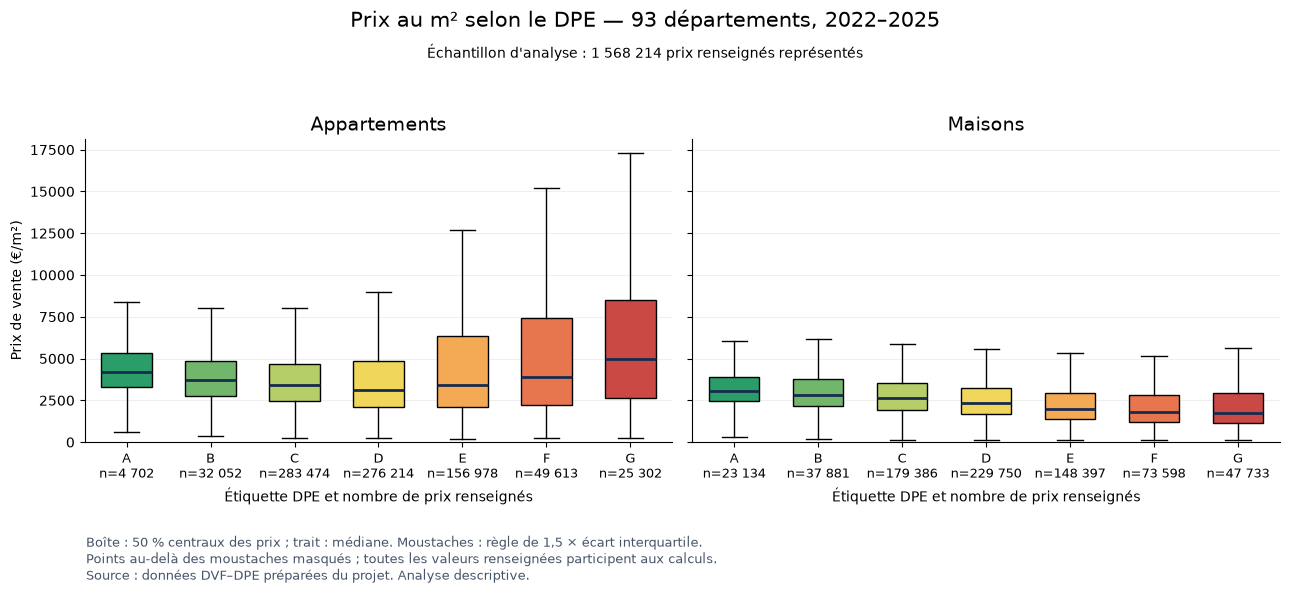

In [6]:
# Construire le graphique à partir de l'échantillon national
fig = boxplots_prix_dpe(
    echantillon,
    titre="Prix au m² selon le DPE — 93 départements, 2022–2025",
)

# Enregistrer une image utilisable dans le rapport
dossier_figures = racine / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

fig.savefig(
    dossier_figures / "boxplots_dpe_france.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

### Comparaison des prix au m² selon le DPE et le type de bien

L'analyse porte sur 1 568 214 ventes appariées à un DPE, réalisées
entre 2022 et 2025 dans les 93 départements couverts par l'étude.
Les ventes rapprochées d'un même logement, espacées de moins de
30 jours, sont exclues selon la règle commune du projet.
L'échantillon comprend 828 335 ventes d'appartements et
739 879 ventes de maisons.

Les comparaisons sont réalisées séparément pour les maisons et
les appartements, dont les caractéristiques et les marchés diffèrent.
La médiane indique le prix au m² en dessous duquel se situe la
moitié des ventes du groupe.

| Classe DPE | Prix médian des appartements (€/m²) | Prix médian des maisons (€/m²) |
|:----------:|------------------------------------:|-------------------------------:|
| A | 4 169,63 | 3 055,68 |
| B | 3 716,41 | 2 845,36 |
| C | 3 427,36 | 2 622,47 |
| D | 3 125,28 | 2 313,73 |
| E | 3 394,68 | 2 010,87 |
| F | 3 869,23 | 1 810,34 |
| G | 4 998,09 | 1 760,00 |

**Maisons.** Le prix médian au m² diminue progressivement lorsque
le classement énergétique se dégrade. Il passe de 3 055,68 €/m²
pour les maisons A à 1 760,00 €/m² pour les maisons G, soit un
écart brut d'environ −42,4 % relativement à la classe A.
Les groupes diffèrent aussi par leur surface médiane :
110 m² en A contre 78 m² en G.

**Appartements.** La relation n'est pas monotone. Le prix médian
diminue de A à D, puis augmente de E à G. Les appartements G
présentent une médiane de 4 998,09 €/m², contre 4 169,63 €/m²
pour les appartements A. Leur surface médiane est toutefois
nettement plus faible : environ 34,2 m² contre 61,2 m².
Cette différence de composition doit être prise en compte
dans l'interprétation des prix au m².

**Lecture du graphique.** Chaque boîte représente les 50 % centraux
des prix du groupe et le trait intérieur indique la médiane.
Les deux panneaux utilisent la même échelle verticale.
Les points au-delà des moustaches sont masqués pour faciliter
la lecture, mais leurs valeurs participent aux calculs.
Les effectifs sont indiqués sous les classes DPE.

**Portée des résultats.** Ces écarts décrivent les ventes retenues
dans l'échantillon et ne permettent pas d'isoler un effet causal
du DPE sur les prix. Des différences de surface, de localisation,
d'ancienneté du bâti ou de période de vente peuvent contribuer
aux écarts observés. L'échantillon de ventes appariées ne représente
pas directement l'ensemble du parc de logements.

*Source : données DVF–DPE préparées par le projet ; calculs à partir
de l'échantillon commun d'analyse.*

In [7]:
# Fixer l'ordre des périodes et des classes DPE
ordre_periodes = [
    "avant 1948",
    "1948-1974",
    "1975-1977",
    "1978-1982",
    "1983-1988",
    "1989-2000",
    "2001-2005",
    "2006-2012",
    "2013-2021",
    "après 2021",
]
ordre_dpe = list("ABCDEFG")

# Préparer les libellés sans modifier les données d'origine
periode = (
    echantillon["periode_construction"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

# Signaler toute catégorie inattendue pour éviter de la perdre
inattendues = set(periode.dropna()) - set(ordre_periodes)
if inattendues:
    raise ValueError(f"Périodes non reconnues : {sorted(inattendues)}")

# Compter les ventes pour chaque combinaison période / DPE
effectifs_construction = pd.crosstab(
    periode.fillna("Non renseignée"),
    echantillon["etiquette_dpe"],
).reindex(
    index=ordre_periodes + ["Non renseignée"],
    columns=ordre_dpe,
    fill_value=0,
)

effectifs_construction.index.name = "periode_construction"
totaux_dpe = effectifs_construction.sum(axis=0)

# Vérifier que toutes les ventes de l'échantillon sont comptées
assert int(totaux_dpe.sum()) == len(echantillon), (
    "Certaines ventes ne sont pas comptées."
)

# Calculer les pourcentages au sein de chaque classe DPE
parts_construction = effectifs_construction.div(
    totaux_dpe.replace(0, float("nan")),
    axis="columns",
).mul(100)

# Chaque colonne non vide doit totaliser 100 % avant arrondi
assert (
    parts_construction.sum()
    .loc[totaux_dpe.gt(0)]
    .sub(100)
    .abs()
    .lt(1e-8)
    .all()
)

# Sauvegarder les effectifs et les pourcentages non arrondis
dossier_tableaux = racine / "reports" / "tables"
dossier_tableaux.mkdir(parents=True, exist_ok=True)

effectifs_construction.to_csv(
    dossier_tableaux / "construction_dpe_effectifs_france.csv",
    encoding="utf-8-sig",
)
parts_construction.to_csv(
    dossier_tableaux / "construction_dpe_france.csv",
    encoding="utf-8-sig",
)

print("Effectif contrôlé :", int(totaux_dpe.sum()))
print(
    "Périodes non renseignées :",
    int(effectifs_construction.loc["Non renseignée"].sum()),
)

# Arrondir uniquement l'affichage
parts_construction.round(1)

Effectif contrôlé : 1568214
Périodes non renseignées : 0


etiquette_dpe,A,B,C,D,E,F,G
periode_construction,,,,,,,
avant 1948,3.6,11.1,15.0,25.9,36.6,44.6,54.7
1948-1974,3.2,10.3,14.9,35.0,46.5,48.7,42.5
1975-1977,0.4,2.0,3.0,5.8,5.1,2.8,1.3
1978-1982,0.8,3.6,5.4,8.5,5.7,2.4,0.9
1983-1988,0.8,4.0,5.7,6.4,3.0,0.8,0.3
1989-2000,2.5,10.1,16.8,10.5,2.4,0.6,0.3
2001-2005,1.6,8.3,9.3,3.2,0.4,0.0,0.0
2006-2012,9.2,25.0,19.8,4.0,0.3,0.0,0.0
2013-2021,68.8,23.8,9.4,0.6,0.0,0.0,0.0


### Périodes de construction selon l’étiquette DPE

Le tableau présente la répartition des périodes de construction
déclarées au sein de chaque classe DPE. Les pourcentages sont
calculés par colonne : chaque classe totalise 100 %, sous réserve
des arrondis d'affichage. La période de construction est renseignée
pour les 1 568 214 ventes de l'échantillon d'analyse.

Les ventes classées A concernent principalement des logements
récents : 68,8 % correspondent à la période 2013–2021 et 9,0 %
à la période postérieure à 2021. Au total, environ 77,9 % des
logements vendus classés A sont déclarés construits depuis 2013.
Ce total est calculé avant l'arrondi des pourcentages.

Les logements anciens sont très présents parmi les classes F
et G. Les constructions antérieures à 1975 représentent 93,3 %
des ventes classées F et 97,2 % des ventes classées G, contre
6,8 % des ventes classées A. Parmi les ventes classées G,
54,7 % concernent des constructions antérieures à 1948.

Ces résultats mettent en évidence une association entre période
de construction et classement énergétique. Ils montrent également
que les classes DPE regroupent des logements de caractéristiques
différentes. Cette composition doit être prise en compte lors
de l'interprétation des écarts de prix.

La description repose sur les périodes déclarées dans les données.
Elle ne constitue pas une vérification de l'année exacte de
construction et ne permet pas d'établir un effet causal de
l'ancienneté sur le DPE. Les proportions concernent les ventes
retenues dans l'échantillon, et non l'ensemble du parc immobilier.

*Source : données DVF–DPE préparées par le projet ; calculs sur
les ventes appariées, hors ventes rapprochées.*

In [8]:
# Lire l'année déclarée et l'année de vente
annee = pd.to_numeric(
    echantillon["annee_construction"], errors="coerce"
)
annee_vente = echantillon["date_mutation"].dt.year

# Retrouver la période correspondant à l'année déclarée
# ordre_periodes a été défini dans la cellule précédente
bornes = [
    float("-inf"), 1947, 1974, 1977, 1982, 1988,
    2000, 2005, 2012, 2021, float("inf"),
]

periode_calculee = pd.cut(
    annee, bins=bornes, labels=ordre_periodes
)
periode_declaree = (
    echantillon["periode_construction"]
    .astype("string")
    .str.strip()
)

coherence = (
    periode_calculee.astype("string")
    .eq(periode_declaree)
    .fillna(False)
)

# Définir les années utilisables sans modifier l'échantillon
annee_valide = (
    annee.gt(0)
    & annee.mod(1).eq(0)
    & annee.le(annee_vente)
    & coherence
)

# Compter trois catégories distinctes couvrant tout l'échantillon
controle_annee = pd.Series(
    {
        "Année absente ou non numérique": int(annee.isna().sum()),
        "Année renseignée non retenue": int(
            (annee.notna() & ~annee_valide).sum()
        ),
        "Année utilisable après contrôles": int(annee_valide.sum()),
    },
    name="nombre_ventes",
)

assert int(controle_annee.sum()) == len(echantillon)

controle_annee.to_frame()

,nombre_ventes
Année absente ou non numérique,598081
Année renseignée non retenue,32535
Année utilisable après contrôles,937598


In [9]:
# Préparer les variables numériques dans un tableau distinct
colonnes_numeriques = [
    "prix_m2",
    "surface",
    "conso_5_usages_par_m2_ep",
]

donnees_correlation = (
    echantillon[colonnes_numeriques]
    .apply(pd.to_numeric, errors="coerce")
    .copy()
)

# Coder l'étiquette dans son ordre naturel : A=1, ..., G=7
rangs_dpe = {
    lettre: rang
    for rang, lettre in enumerate("ABCDEFG", start=1)
}

donnees_correlation["rang_dpe"] = (
    echantillon["etiquette_dpe"].map(rangs_dpe).astype(float)
)

# Une année non retenue devient manquante uniquement dans ce tableau
donnees_correlation["annee_construction"] = annee.where(
    annee_valide
)

# Calculer les corrélations de Spearman
correlations = donnees_correlation.corr(method="spearman")

# Compter les observations disponibles pour chaque paire
presences = donnees_correlation.notna().astype("int64")
effectifs_correlations = presences.T.dot(presences)

# Sauvegarder les résultats sans arrondir les coefficients
dossier_tableaux = racine / "reports" / "tables"
dossier_tableaux.mkdir(parents=True, exist_ok=True)

exports = {
    "controle_annee_construction_france.csv": controle_annee,
    "correlations_spearman_france.csv": correlations,
    "effectifs_correlations_france.csv": effectifs_correlations,
}

for nom, tableau in exports.items():
    tableau.to_csv(
        dossier_tableaux / nom,
        encoding="utf-8-sig",
    )

print("Corrélations de Spearman :")
display(correlations.round(3))

print("Nombre de ventes utilisé pour chaque corrélation :")
display(effectifs_correlations)

Corrélations de Spearman :


,prix_m2,surface,conso_5_usages_par_m2_ep,rang_dpe,annee_construction
prix_m2,1.000,-0.284,-0.095,-0.132,0.165
surface,-0.284,1.000,-0.177,-0.090,0.038
conso_5_usages_par_m2_ep,-0.095,-0.177,1.000,0.921,-0.568
rang_dpe,-0.132,-0.090,0.921,1.000,-0.563
annee_construction,0.165,0.038,-0.568,-0.563,1.000


Nombre de ventes utilisé pour chaque corrélation :


,prix_m2,surface,conso_5_usages_par_m2_ep,rang_dpe,annee_construction
prix_m2,1568214,1568214,1568087,1568214,937598
surface,1568214,1568214,1568087,1568214,937598
conso_5_usages_par_m2_ep,1568087,1568087,1568087,1568087,937496
rang_dpe,1568214,1568214,1568087,1568214,937598
annee_construction,937598,937598,937496,937598,937598


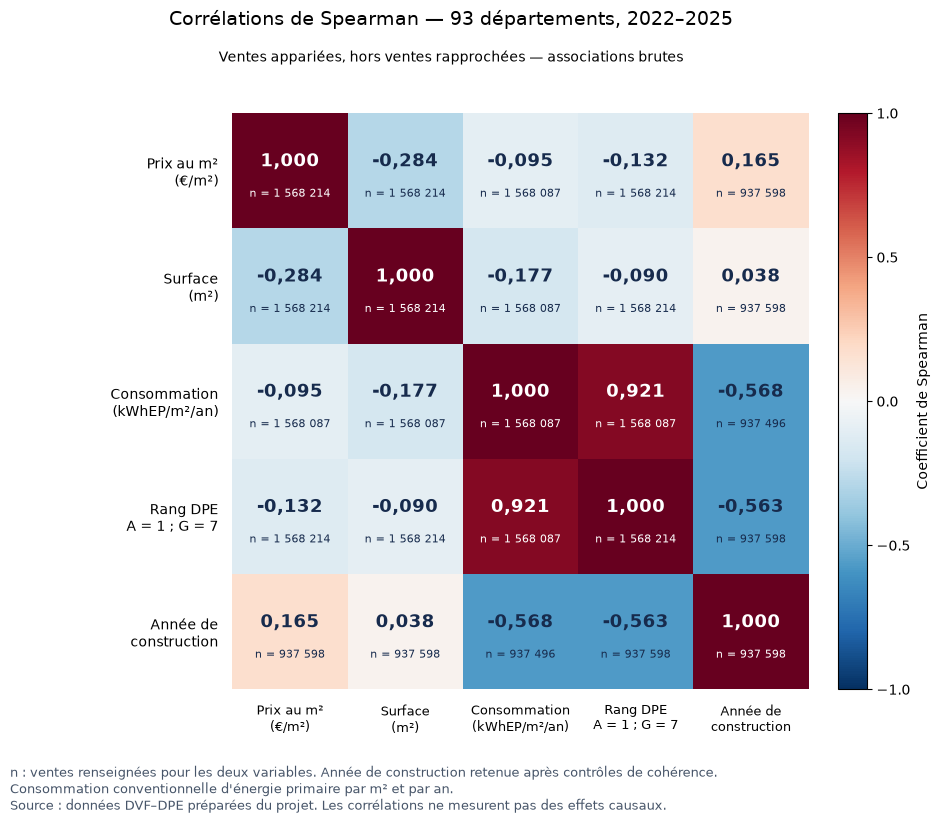

In [10]:
# Prendre en compte la fonction ajoutée au fichier
importlib.reload(graphiques)

# Construire la figure à partir des résultats déjà calculés
fig = graphiques.matrice_spearman(
    correlations,
    effectifs_correlations,
    titre="Corrélations de Spearman — 93 départements, 2022–2025",
)

# Enregistrer les versions pour le rapport
dossier_figures = racine / "reports" / "figures"
dossier_figures.mkdir(parents=True, exist_ok=True)

fig.savefig(
    dossier_figures / "correlations_spearman_france.png",
    dpi=250,
    bbox_inches="tight",
)
fig.savefig(
    dossier_figures / "correlations_spearman_france.pdf",
    bbox_inches="tight",
)

plt.show()

### Corrélations de Spearman

La matrice croise le prix au m², la surface, la consommation
énergétique par m², le rang de l'étiquette DPE et l'année de
construction. Le rang DPE est codé de 1 pour A à 7 pour G.

Les coefficients de Spearman mesurent l'association entre les
rangs des variables. Un coefficient positif indique une tendance
à augmenter ensemble ; un coefficient négatif indique des
évolutions de sens opposé. Ces coefficients ne sont pas des
variations de prix en pourcentage.

**Principaux résultats**

- La consommation énergétique est fortement associée au rang DPE
  (0,921) : les logements présentant une consommation plus élevée
  tendent à avoir un classement moins favorable.
- L'année de construction est négativement associée à la
  consommation (−0,568) et au rang DPE (−0,563). Les constructions
  déclarées plus récentes tendent donc à présenter une consommation
  plus faible et un meilleur classement.
- Le prix au m² est faiblement associé au rang DPE (−0,132)
  et à la consommation énergétique (−0,095).
- La surface est négativement associée au prix au m² (−0,284).
  L'association entre année de construction et prix au m² est
  positive et faible (0,165).

**Qualité des données et effectifs**

L'année de construction est absente pour 598 081 ventes.
Parmi les années renseignées, 32 535 ne sont pas retenues :
32 529 sont incompatibles avec la période déclarée et 6 sont
cohérentes avec cette période mais postérieures à la vente.
Aucune année manquante ou incohérente n'est remplacée par
une valeur estimée.

Chaque coefficient utilise les observations disponibles pour
les deux variables concernées. Les corrélations entre prix,
surface et rang DPE portent sur 1 568 214 ventes.
Celles de ces variables avec la consommation en utilisent
1 568 087.

Les corrélations impliquant l'année de construction portent
sur 937 598 ventes, ou 937 496 lorsqu'elles impliquent également
la consommation. La matrice des effectifs est sauvegardée
avec celle des coefficients.

Ces associations sont descriptives et ne contrôlent pas les
différences de localisation, de type de bien ou de période de
vente. Les ventes dont l'année de construction est exploitable
peuvent également différer du reste de l'échantillon.

*Source : données DVF–DPE préparées par le projet ; calculs sur
les ventes appariées, hors ventes rapprochées.*

Départements avec observations : 93
Ventes retenues : 1568214
Ventes F/G : 196246
Part F/G : 12.51 %
Départements sans observation : ['57', '67', '68']


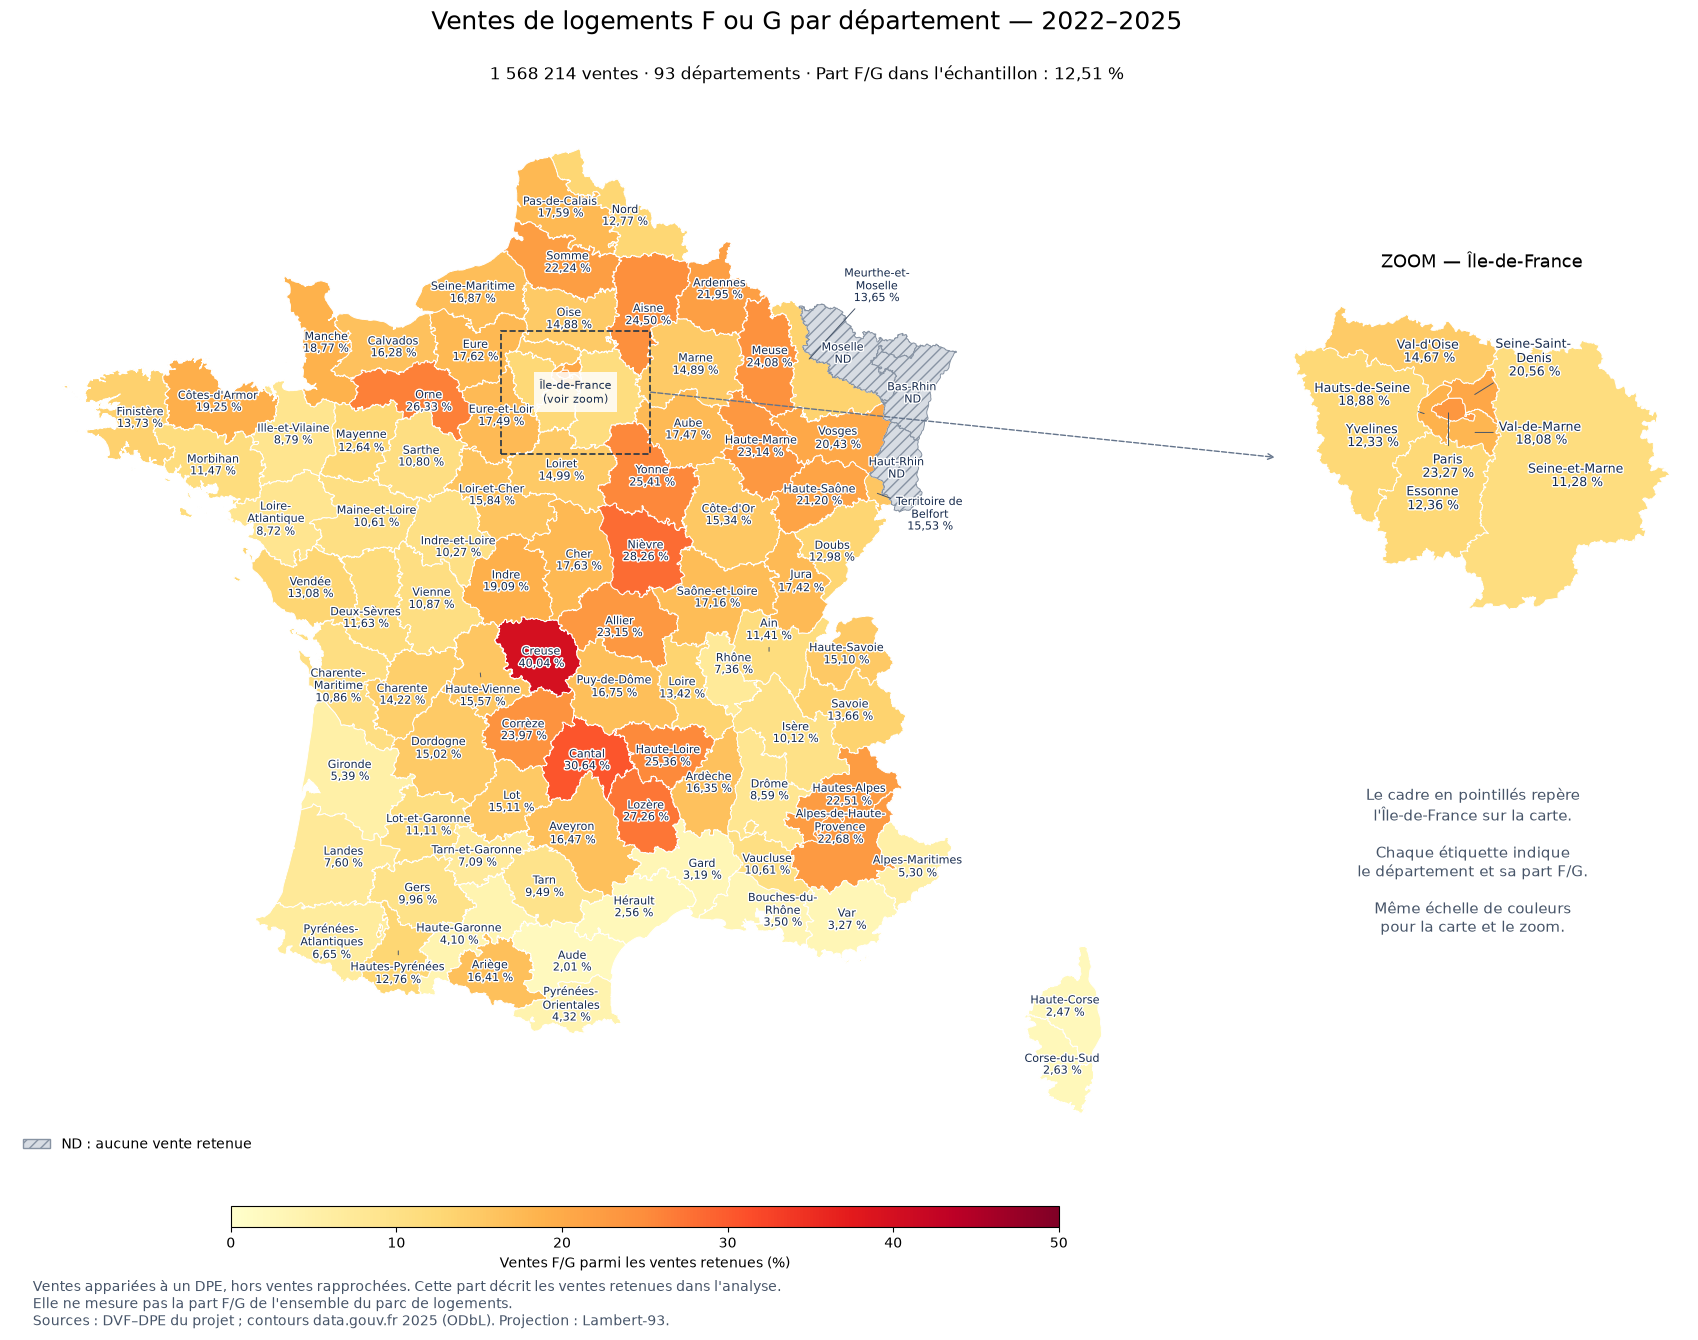

In [11]:
# Charger la version enregistrée des fonctions de cartographie
cartographie = importlib.import_module("src.cartographie")
importlib.reload(cartographie)

# Calculer les parts F/G sur l'échantillon national
tableau_fg = cartographie.parts_fg(echantillon)

# Vérifier que toutes les ventes sont comptées
assert tableau_fg["nombre_ventes"].sum() == len(echantillon)
assert tableau_fg["nombre_fg"].sum() == (
    echantillon["etiquette_dpe"].isin(["F", "G"]).sum()
)

# Charger le fond de carte vérifié
fond = cartographie.fond_departements(racine / "data" / "external")

# Préparer les dossiers de sortie
dossier_figures = racine / "reports" / "figures"
dossier_tableaux = racine / "reports" / "tables"
dossier_figures.mkdir(parents=True, exist_ok=True)
dossier_tableaux.mkdir(parents=True, exist_ok=True)

# Enregistrer les effectifs et les pourcentages sans les arrondir
tableau_fg_export = tableau_fg.merge(
    fond[["code_departement", "nom"]],
    on="code_departement",
    validate="one_to_one",
)
tableau_fg_export = tableau_fg_export[
    ["code_departement", "nom", "nombre_ventes", "nombre_fg", "part_fg_pct"]
]
tableau_fg_export.to_csv(
    dossier_tableaux / "carte_part_fg_france.csv",
    index=False,
    encoding="utf-8-sig",
)

# Dessiner la carte avec les noms et les pourcentages
fig = cartographie.carte_fg(
    tableau_fg,
    fond,
    titre="Ventes de logements F ou G par département — 2022–2025",
)

# Enregistrer une image et un PDF
for extension in ("png", "pdf"):
    fig.savefig(
        dossier_figures / f"carte_part_fg_france_noms.{extension}",
        dpi=250,
        bbox_inches="tight",
    )

# Afficher les contrôles
total_ventes = int(tableau_fg["nombre_ventes"].sum())
total_fg = int(tableau_fg["nombre_fg"].sum())
part_fg_totale = 100 * total_fg / total_ventes

sans_observation = sorted(
    set(fond["code_departement"]) - set(tableau_fg["code_departement"])
)

print("Départements avec observations :", len(tableau_fg))
print("Ventes retenues :", total_ventes)
print("Ventes F/G :", total_fg)
print(f"Part F/G : {part_fg_totale:.2f} %")
print("Départements sans observation :", sans_observation)

plt.show()

### Répartition géographique des ventes de logements classés F ou G

Pour chaque département, la part F/G correspond au nombre de ventes
retenues de logements classés F ou G, divisé par le nombre total de
ventes retenues dans ce département.

Dans l'échantillon étudié, les logements F ou G représentent
196 246 ventes sur 1 568 214, soit **12,51 %**. Cette proportion est
calculée sur les effectifs totaux, et non comme une moyenne simple
des pourcentages départementaux.

Les différences géographiques sont marquées : la part atteint
**40,04 % dans la Creuse**, **30,64 % dans le Cantal** et
**28,26 % dans la Nièvre**. Elle est plus faible dans l'Aude
(2,01 %), en Haute-Corse (2,47 %) et dans l'Hérault (2,56 %).

La Moselle, le Bas-Rhin et le Haut-Rhin sont grisés car ils ne
comptent aucune observation dans l'échantillon utilisé.

Ces résultats décrivent les ventes appariées retenues dans l'analyse.
Ils ne permettent pas d'estimer directement la part des logements
F/G dans l'ensemble du parc immobilier. Les écarts observés peuvent
notamment refléter la composition des biens vendus et la sélection
liée à l'appariement.

*Sources : données DVF–DPE préparées du projet ; contours administratifs
data.gouv.fr, millésime 2025, généralisation 100 m.*